# Theorem 9 with two risky assets and two factors: from the Schrödinger equation back to $u$

Linear PDE (main.tex, Theorem 2, Eqs. (11), (14)), $y=(y_1,y_2)$:
$$
\partial_t u(t,y)+\mathcal L u(t,y)=0,\qquad u(T,y)=1,\qquad
\mathcal L=\tfrac12\sum_{s,s'=1}^{2}a_{ss'}(y)\,\partial_{y_sy_{s'}}+\sum_{s=1}^{2}b_s(y)\,\partial_{y_s}+P(y).
$$
$$
u\ \xrightarrow{\ \text{Prop. 8}\ }\ \frac{d\boldsymbol u}{d\tau}=\boldsymbol{\mathcal L}\boldsymbol u
\ \xrightarrow{\ \text{Thm. 9}\ }\ i\frac{d\widetilde{\boldsymbol w}}{d\tau}=H\widetilde{\boldsymbol w}
\ \Rightarrow\ \widetilde{\boldsymbol w}(T)=e^{-iHT}\,\widetilde{\boldsymbol w}(0)
\ \xrightarrow{\ \text{Eq. (78)}\ }\ u(0,\cdot).
$$

In [20]:
from functools import reduce
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.linalg import expm
from scipy.integrate import solve_ivp

## 1. Setting

$n=k=d_W=d_B=2$, $T=1$, $\gamma=0.5$, $\alpha\equiv0$, constant invertible $\sigma$ with $\mu(y)=\sigma^\top\lambda(y)$,
$$
\kappa=\begin{pmatrix}1&0.3\\0&\sqrt{0.91}\end{pmatrix},\qquad
\rho=\begin{pmatrix}1&0\\0&1\end{pmatrix},\qquad
\lambda(y)=\begin{pmatrix}0.5+0.3\cos y_1\\ 0.4+0.2\sin y_2\end{pmatrix}.
$$
Then $\rho^\top\rho=I_2$ (EVE, $p=1$), $\Gamma=\frac{1-\gamma}{\gamma}=1$, $q=\frac{1}{1+\Gamma p}=0.5$, and the coefficients (Eq. (10)) are
$$
a=\kappa^\top\kappa=\begin{pmatrix}1&0.3\\0.3&1\end{pmatrix},\qquad
b(y)=\Gamma\,\kappa^\top\rho^\top\lambda(y)=\begin{pmatrix}\lambda_1(y)\\ 0.3\,\lambda_1(y)+\sqrt{0.91}\,\lambda_2(y)\end{pmatrix},\qquad
P(y)=\frac{\Gamma}{2q}\,\|\lambda(y)\|^2=\lambda_1(y)^2+\lambda_2(y)^2.
$$
$a,b,P$ are $2\pi$-periodic in $y_1$ and $y_2$, so $u(t,\cdot)$ is too and the periodic domain $[-\pi,\pi)^2$ ($R=\pi$) is exact.

In [21]:
k, T, gamma = 2, 1.0, 0.5
kappa = np.array([[1.0, 0.3], [0.0, np.sqrt(0.91)]])                     # d_B x k
rho = np.eye(2)                                                           # d_W x d_B
lam = lambda y: np.stack([0.5 + 0.3 * np.cos(y[0]), 0.4 + 0.2 * np.sin(y[1])])   # d_W x points, y has shape (k, points)

p = (rho.T @ rho)[0, 0]                                                   # rho^T rho = p I_2, p = 1
Gamma = (1 - gamma) / gamma                                               # = 1
q = 1 / (1 + Gamma * p)                                                   # = 0.5
a = kappa.T @ kappa                                                       # = [[1, 0.3], [0.3, 1]]
b = lambda y: Gamma * kappa.T @ rho.T @ lam(y)                            # k x points
P = lambda y: Gamma / (2 * q) * np.sum(lam(y)**2, axis=0)                 # points

## 2. Fourier discretisation in $y$ (Prop. 8), $M=16$, $R=\pi$

$$
y_j=-R+(j-1)\,\tfrac{2R}{M},\qquad \mu_l=\tfrac{\pi(l-M/2-1)}{R},\qquad
\Phi_{jl}=e^{i\mu_l y_j},\qquad P_\mu=\Phi D_\mu\Phi^{-1}\ \ \text{(Eqs. (53), (55))},
$$
$$
y_{\boldsymbol j}=(y_{j_1},y_{j_2})\ \ \text{(last index fastest, Eq. (56))},\qquad
\boldsymbol P_1=P_\mu\otimes I_M,\quad \boldsymbol P_2=I_M\otimes P_\mu\ \ \text{(Eq. (57))},\qquad N=M^2,
$$
$$
\boldsymbol{\mathcal L}=-\tfrac12\sum_{s,s'=1}^{2}\mathrm{diag}(a_{ss'})\,\boldsymbol P_s\boldsymbol P_{s'}+i\sum_{s=1}^{2}\mathrm{diag}(b_s)\,\boldsymbol P_s+\mathrm{diag}(P)\ \ \text{(Eq. (59))},
\qquad
\frac{d\boldsymbol u}{d\tau}=\boldsymbol{\mathcal L}\boldsymbol u,\quad \boldsymbol u(0)=\boldsymbol 1_N\ \ \text{(Eq. (60))},\quad \tau=T-t .
$$

In [22]:
def fourier(M, R):
    """Grid x_j, Fourier matrix Phi_{jl} = exp(i mu_l x_j), D_mu = diag(mu_l)."""
    x = -R + 2 * R * np.arange(M) / M
    mu = np.pi * (np.arange(1, M + 1) - M / 2 - 1) / R
    return x, np.exp(1j * np.outer(x, mu)), np.diag(mu)

M, R = 16, np.pi
N = M**k
y1, Phi, D_mu = fourier(M, R)
P_mu = Phi @ D_mu @ np.linalg.inv(Phi)                                         # represents -i d/dy
P_s = [reduce(np.kron, [P_mu if t == s else np.eye(M) for t in range(k)]) for s in range(k)]
Y = np.stack([g.ravel() for g in np.meshgrid(*[y1] * k, indexing="ij")])     # k x N, last index fastest

L = (-0.5 * sum(a[s, t] * P_s[s] @ P_s[t] for s in range(k) for t in range(k))
     + 1j * sum(np.diag(b(Y)[s]) @ P_s[s] for s in range(k))
     + np.diag(P(Y)))
print("L:", L.shape)

L: (256, 256)


## 3. Schrödinger equation (Theorem 9)

$$
H_1=\frac{\boldsymbol{\mathcal L}+\boldsymbol{\mathcal L}^\dagger}{2},\qquad
H_2=\frac{\boldsymbol{\mathcal L}-\boldsymbol{\mathcal L}^\dagger}{2i}\ \ \text{(Eq. (70))},\qquad
c=\lambda_{\max}(H_1).
$$
$h$-grid: same construction with $(h,R_h,M_h)$ in place of $(y,R,M)$, $R_h=8$, $M_h=256$ (main.tex takes $M_h=M$), giving $h_j$, $\Phi_h$, $D_{\mu,h}=\mathrm{diag}(\mu^h_1,\dots,\mu^h_{M_h})$, $\mu^h_l=\frac{\pi(l-M_h/2-1)}{R_h}$:
$$
H=(H_1-cI_N)\otimes D_{\mu,h}-H_2\otimes I_{M_h}\ \ \text{(Eq. (76))},\qquad
\widetilde{\boldsymbol w}(0)=\boldsymbol 1_N\otimes\Phi_h^{-1}\big(e^{-|h_1|},\dots,e^{-|h_{M_h}|}\big)^\top,
$$
$$
i\frac{d\widetilde{\boldsymbol w}}{d\tau}=H\widetilde{\boldsymbol w}\ \ \text{(Eq. (77))}
\quad\Rightarrow\quad
\widetilde{\boldsymbol w}(T)=e^{-iHT}\,\widetilde{\boldsymbol w}(0).
$$
$D_{\mu,h}$ is diagonal, so $H$ is block diagonal. With $\widetilde{\boldsymbol w}_{\cdot,l}:=(\widetilde w_{1,l},\dots,\widetilde w_{N,l})^\top$ ($\widetilde w_{i,l}$ at position $(i-1)M_h+l$, Eq. (75)):
$$
\widetilde{\boldsymbol w}_{\cdot,l}(T)=e^{-iT\left(\mu^h_l(H_1-cI_N)-H_2\right)}\,\widetilde{\boldsymbol w}_{\cdot,l}(0),\qquad l=1,\dots,M_h .
$$

In [23]:
H1 = (L + L.conj().T) / 2
H2 = (L - L.conj().T) / 2j
c = np.linalg.eigvalsh(H1).max()

M_h, R_h = 256, 8.0
h, Phi_h, D_mu_h = fourier(M_h, R_h)                     # own number of points M_h for h
mu_h = np.diag(D_mu_h)
W0 = np.outer(np.ones(N), np.linalg.solve(Phi_h, np.exp(-np.abs(h))))   # W0[i, l] = w~_{i,l}(0), w~(0) = W0.ravel()

WT = np.stack([expm(-1j * T * (mu_h[l] * (H1 - c * np.eye(N)) - H2)) @ W0[:, l]
               for l in range(M_h)], axis=1)             # column l = block l of e^{-iHT} w~(0)
print(f"N * M_h = {N * M_h}, c = {c:.4f}")

N * M_h = 65536, c = 0.6093


## 4. Recover $u$ (Eq. (78))

At the grid point $h_j=0.5$ and $\tau=T$ (i.e. $t=0$), with $\phi_l(h)=e^{i\mu^h_l h}$:
$$
\big(u(0,y_{(1,1)}),\dots,u(0,y_{(M,M)})\big)^\top\approx e^{h_j+cT}\Big[I_N\otimes\big(\phi_1(h_j)\ \cdots\ \phi_{M_h}(h_j)\big)\Big]\,\widetilde{\boldsymbol w}(T)
=e^{h_j+cT}\sum_{l=1}^{M_h}\phi_l(h_j)\,\widetilde{\boldsymbol w}_{\cdot,l}(T).
$$
Prop. 8 solution: $u^{\mathrm{Prop.\,8}}:=\boldsymbol u(T)=e^{T\boldsymbol{\mathcal L}}\boldsymbol 1_N$ (Eq. (60)).

In [24]:
j = np.argmin(np.abs(h - 0.5))                            # grid point h_j = 0.5
u_rec = np.exp(h[j] + c * T) * (WT @ Phi_h[j])            # Phi_h[j] = (phi_1(h_j), ..., phi_{M_h}(h_j))
u_prop8 = expm(T * L) @ np.ones(N)                        # Eq. (60)
print(f"h_j = {h[j]:.4f}")

h_j = 0.5000


## 5. Reference $u^{\mathrm{ref}}$: Theorem 2 solved directly by finite differences + RK45

$\tau=T-t$ in Eq. (14):
$$
\partial_\tau u=\tfrac12\sum_{s,s'=1}^{2}a_{ss'}\,\partial_{y_sy_{s'}}u+\sum_{s=1}^{2}b_s\,\partial_{y_s}u+Pu,\qquad u(\tau=0,y)=1 .
$$
Periodic $n\times n$ grid on $[-\pi,\pi)^2$, $n=256$, $\Delta=2\pi/n$, central differences, applied twice for second derivatives:
$$
\partial_{y_s}u\approx\frac{u_{\boldsymbol j+\boldsymbol e_s}-u_{\boldsymbol j-\boldsymbol e_s}}{2\Delta},\qquad
\partial_{y_sy_{s'}}u\approx\partial_{y_s}\big(\partial_{y_{s'}}u\big),\qquad \text{error } O(\Delta^2).
$$


In [25]:
n = 256
d = 2 * np.pi / n
yn = -np.pi + d * np.arange(n)
Yn = np.stack([g.ravel() for g in np.meshgrid(yn, yn, indexing="ij")])
bn, Pn = b(Yn).reshape(k, n, n), P(Yn).reshape(n, n)

D = lambda V, ax: (np.roll(V, -1, ax) - np.roll(V, 1, ax)) / (2 * d)    # periodic central difference along axis ax

def rhs(tau, u):
    U = u.reshape(n, n)
    U1, U2 = D(U, 0), D(U, 1)
    U11, U12, U22 = D(U1, 0), D(U1, 1), D(U2, 1)
    return (0.5 * (a[0, 0] * U11 + 2 * a[0, 1] * U12 + a[1, 1] * U22)
            + bn[0] * U1 + bn[1] * U2 + Pn * U).ravel()

sol = solve_ivp(rhs, [0, T], np.ones(n * n), method="RK45", rtol=1e-10, atol=1e-10)
u_ref = sol.y[:, -1].reshape(n, n)[::n // M, ::n // M].ravel()           # reference on the M x M grid

rel = lambda v: np.linalg.norm(v - u_ref) / np.linalg.norm(u_ref)
print(f"u(0, y) range: [{u_ref.min():.4f}, {u_ref.max():.4f}]")
print("relative L2 error, Prop. 8 (Eq. (60)):   ", rel(u_prop8))
print("relative L2 error, Theorem 9 (Eq. (78)): ", rel(u_rec))

u(0, y) range: [1.1587, 2.3541]
relative L2 error, Prop. 8 (Eq. (60)):    1.6183515936646766e-05
relative L2 error, Theorem 9 (Eq. (78)):  0.0004243413206429389


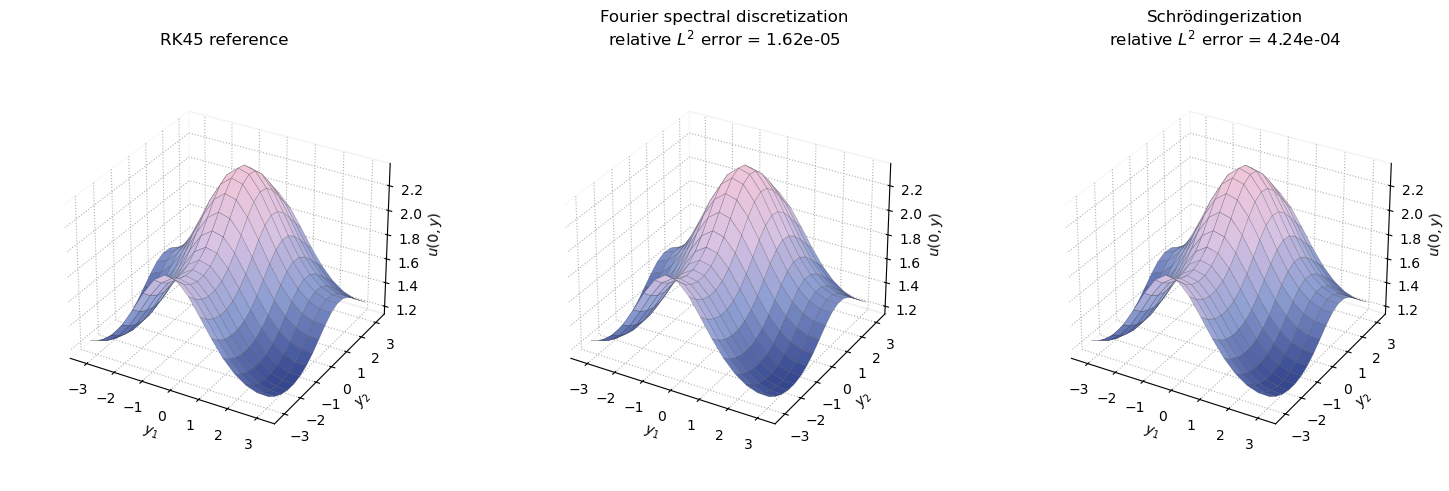

In [29]:
yc = np.append(y1, np.pi)                                          # close the periodic grid: u(y = pi) = u(y = -pi)
Y1, Y2 = np.meshgrid(yc, yc, indexing="ij")
Z = lambda v: np.pad(v.real.reshape(M, M), (0, 1), mode="wrap")    # Z[j1, j2] = u(0, y_{j1}, y_{j2})
blue_pink = LinearSegmentedColormap.from_list("blue_pink", ["#34478f", "#8e9fd3", "#d9c3e3", "#f0c6d8"])   # low u: blue, high u: pink

with plt.rc_context({"grid.linestyle": ":"}):                      # dotted grid
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), subplot_kw={"projection": "3d"}, layout="constrained")
    for a_, v, title in [(ax[0], u_ref, "RK45 reference"),
                         (ax[1], u_prop8, f"Fourier spectral discretization\nrelative $L^2$ error = {rel(u_prop8):.2e}"),
                         (ax[2], u_rec, f"Schrödingerization\nrelative $L^2$ error = {rel(u_rec):.2e}")]:
        a_.plot_surface(Y1, Y2, Z(v), cmap=blue_pink, vmin=u_ref.min(), vmax=u_ref.max(),
                        edgecolor=(0.2, 0.2, 0.2, 0.35), linewidth=0.4)   # colour by u, mesh lines with alpha = 0.25
        a_.set(title=title, xlabel="$y_1$", ylabel="$y_2$", zlabel="$u(0,y)$", zlim=(u_ref.min(), u_ref.max()))
        a_.set_box_aspect(None, zoom=0.85)                         # smaller box keeps the z label inside the figure
        for axis in (a_.xaxis, a_.yaxis, a_.zaxis):
            axis.pane.fill = False                                 # no grey background panes
    plt.show()